# 13 · Adapt a model to a domain

    **Question.** Does a remittance workflow need new vocabulary, better evidence use or both?

    Compare a fixed evidence prompt, continued language modelling, reading-comprehension SFT and RAFT-style SFT on the same held-out documents. Keep an invoice extraction regression check beside the new task.

## Runtime

Select a Tesla T4 in Colab. Each branch runs in sequence. Model downloads use the
public Hugging Face checkpoint, pinned by revision. The shared runtime can reuse
its weight cache. The material below embeds the invoice fixtures and training code.

In [1]:
import subprocess
import sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *['transformers==4.51.3', 'peft==0.15.2', 'accelerate==1.6.0']], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'transformers==4.51.3', 'peft==0.15.2', 'accelerate==1.6.0'], returncode=0)

In [2]:
import torch
if not torch.cuda.is_available() or "T4" not in torch.cuda.get_device_name(0):
    raise RuntimeError("Select a Tesla T4 runtime in Colab before running this notebook.")
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

GPU: Tesla T4
PyTorch: 2.14.1+cu130


## Invoice fixtures

The synthetic input and gold record come from a versioned scenario. The scorer compares
generated JSON with the gold record independently of model training. The release set stays
out of this lesson.

In [3]:
"""Versioned synthetic invoices and independent record scoring for the course."""

from __future__ import annotations

import json
import random
import re
from collections import Counter
from dataclasses import dataclass
from datetime import date, timedelta
from typing import Any

CATALOG_VERSION = "course-invoice-v1"
SPLIT_SIZES = {"train": 576, "dev": 72, "familiar": 96, "novel": 96, "independent": 48, "release": 120}
VISIBLE_CONTRACT = (
    "Extract exactly one JSON object with invoice_id, issued_on (YYYY-MM-DD), supplier, "
    "currency (ISO code), line_items (description, quantity, unit_minor), subtotal_minor, "
    "tax_minor, and total_minor. Preserve line order and convert currency amounts to integer cents. "
    "Use null only for a missing or ambiguous field. Do not rewrite printed amounts, invent fields, or add explanations."
)

@dataclass(frozen=True)
class Line:
    description: str
    quantity: int
    unit_minor: int


@dataclass(frozen=True)
class Invoice:
    key: str
    family: str
    supplier: str
    issued_on: str
    currency: str
    items: tuple[Line, ...]
    tax_minor: int | None
    locale: str
    split: str
    layout: str = "register"
    printed_total_minor: int | None = None


def invoice_record(invoice: Invoice) -> dict[str, Any]:
    subtotal = sum(line.quantity * line.unit_minor for line in invoice.items)
    total = subtotal + invoice.tax_minor if invoice.tax_minor is not None else None
    if invoice.printed_total_minor is not None:
        total = invoice.printed_total_minor
    return {
        "invoice_id": invoice.key,
        "issued_on": invoice.issued_on,
        "supplier": invoice.supplier,
        "currency": invoice.currency,
        "line_items": [
            {"description": item.description, "quantity": item.quantity, "unit_minor": item.unit_minor}
            for item in invoice.items
        ],
        "subtotal_minor": subtotal,
        "tax_minor": invoice.tax_minor,
        "total_minor": total,
    }


def make_catalog() -> list[Invoice]:
    rng = random.Random(20261126)
    sources = {
        "train": (24, ("register", "memo", "checkout", "ledger")),
        "dev": (6, ("register", "memo", "checkout", "ledger")),
        "familiar": (8, ("register", "memo", "checkout", "ledger")),
        "novel": (8, ("packing", "remittance", "service", "notice")),
        "independent": (4, ("separate",)),
        "release": (10, ("packing", "remittance", "service", "notice", "separate")),
    }
    locales = (("en-US", "USD"), ("en-GB", "GBP"), ("de-DE", "EUR"), ("fr-FR", "EUR"), ("en-US", "CAD"))
    services = ("Cooling filter", "Cable sleeve", "Bench calibration", "Door seal", "Grounding clip",
                "Rack inspection", "Meter label", "Packing insert", "Carrier adjustment", "Mounting plate")
    catalog = []
    seen_keys = set()
    supplier_codes = rng.sample(range(1000, 9999), sum(n for n, _ in sources.values()))
    supplier_index = 0
    for split, (family_count, layouts) in sources.items():
        for family_number in range(family_count):
            supplier_code = supplier_codes[supplier_index]
            supplier_index += 1
            layout = layouts[family_number % len(layouts)]
            family = f"{split}-{family_number:02d}"
            locale, currency = locales[family_number % len(locales)]
            for row in range(SPLIT_SIZES[split] // family_count):
                code = f"SF-{rng.randrange(100000, 1000000)}"
                while code in seen_keys:
                    code = f"SF-{rng.randrange(100000, 1000000)}"
                seen_keys.add(code)
                items = tuple(
                    Line(kind, rng.randint(1, 9), rng.randrange(200, 24800))
                    for kind in rng.sample(services, rng.randrange(1, 4))
                )
                subtotal = sum(x.quantity * x.unit_minor for x in items)
                tax = (subtotal * (7 if currency == "USD" else 13) + 50) // 100
                if split in {"novel", "independent", "release"} and row % 12 == 4:
                    tax = None
                displayed = subtotal + tax + 101 if tax is not None and row % 12 == 7 else None
                issued_on = (date(2025, 1, 1) + timedelta(days=rng.randint(0, 590))).isoformat()
                catalog.append(Invoice(code, family, f"Sample Supplier {supplier_code}", issued_on,
                                       currency, items, tax, locale, split, layout, displayed))
    return catalog


def formatted_money(minor: int | None, locale: str) -> str:
    if minor is None:
        return "-"
    dollars, cents = divmod(minor, 100)
    number = f"{dollars:,}.{cents:02d}"
    if locale == "de-DE":
        return number.replace(",", "_").replace(".", ",").replace("_", ".")
    if locale == "fr-FR":
        return number.replace(",", " ").replace(".", ",")
    return number


def invoice_text(invoice: Invoice) -> str:
    gold = invoice_record(invoice)
    money = lambda value: formatted_money(value, invoice.locale)
    identifier = f"{invoice.key}"
    supplier = invoice.supplier
    issued = invoice.issued_on
    currency = invoice.currency
    subtotal = money(gold["subtotal_minor"])
    tax = money(gold["tax_minor"])
    total = money(gold["total_minor"])
    register = [f"{row.description} | {row.quantity} | {money(row.unit_minor)}" for row in invoice.items]
    inline = [f"{row.quantity} x {row.description} @ {money(row.unit_minor)} per unit" for row in invoice.items]
    service = [f"{row.description}: {money(row.unit_minor)} each for {row.quantity} units" for row in invoice.items]
    if invoice.layout == "register":
        return "\n".join([f"Supplier: {supplier}", f"Invoice: {identifier}", f"Issued: {issued}", f"Currency: {currency}",
                          "Description | Quantity | Unit price", *register,
                          f"Subtotal: {subtotal}", f"Tax: {tax}", f"Amount due: {total}"])
    if invoice.layout == "memo":
        return "\n".join([f"{supplier} billing memo / {issued}", f"Account invoice {identifier} [{currency}]",
                          *inline, f"Total due {total} including tax {tax}; net amount {subtotal}."])
    if invoice.layout == "checkout":
        return "\n".join([f"{identifier} / supplier {supplier}", f"Date of issue {issued} / All amounts {currency}",
                          *service, f"Net {subtotal}", f"Sales tax {tax}", f"Payable {total}"])
    if invoice.layout == "ledger":
        return "\n".join([f"{supplier} | issued {issued} | invoice {identifier}", f"Ledger in {currency}",
                          "Service | Count | Per unit", *register, f"Before tax {subtotal}",
                          f"Tax charged {tax}", f"Balance {total}"])
    if invoice.layout == "packing":
        return "\n".join([f"Billing details / {identifier}", f"Sold by {supplier}", f"Document date {issued}",
                          f"Invoice currency {currency}", f"Balance payable {total}", *service,
                          f"Merchandise {subtotal}", f"Tax {tax}"])
    if invoice.layout == "remittance":
        return "\n".join([f"Remittance advice for {identifier} ({currency})", f"{supplier} / Document issued {issued}",
                          f"Pay this amount {total}", *inline, f"Net charges {subtotal} / Tax {tax}"])
    if invoice.layout == "service":
        return "\n".join([f"Ref {identifier} / {currency}", f"Service fee notice, {issued}", supplier,
                          *[f"Unit {money(row.unit_minor)} / {row.quantity} times / {row.description}" for row in invoice.items],
                          f"Fee subtotal {subtotal}", f"Plus tax {tax}", f"Amount requested {total}"])
    if invoice.layout == "notice":
        return "\n".join([f"{supplier} / statement {identifier}", f"Issued on {issued}",
                          f"Invoice denomination {currency}", "One-off charges", *service,
                          f"Pre-tax {subtotal} / Tax assessment {tax} / Final bill {total}"])
    return "\n".join([f"Document {identifier}", f"Biller {supplier} / As of {issued} / {currency}", *inline,
                      f"Gross {total}", f"Breakdown: net {subtotal} and taxes {tax}."])


def _strict_dict(pairs: list[tuple[str, Any]]) -> dict[str, Any]:
    result: dict[str, Any] = {}
    for key, value in pairs:
        if key in result:
            raise ValueError(f"Duplicate JSON key {key!r}")
        result[key] = value
    return result


def parse_record(completion: str | dict[str, Any]) -> dict[str, Any] | None:
    if isinstance(completion, str):
        try:
            data = json.loads(completion, object_pairs_hook=_strict_dict)
        except (ValueError, TypeError, RecursionError):
            return None
    else:
        data = completion
    keys = {"invoice_id", "issued_on", "supplier", "currency", "line_items", "subtotal_minor", "tax_minor", "total_minor"}
    if not isinstance(data, dict) or set(data) != keys:
        return None
    for name in ("invoice_id", "supplier", "issued_on", "currency"):
        value = data[name]
        if value is not None and (not isinstance(value, str) or not value.strip()):
            return None
    try:
        if data["issued_on"] is not None and date.fromisoformat(data["issued_on"]).isoformat() != data["issued_on"]:
            return None
    except ValueError:
        return None
    if data["currency"] is not None and re.fullmatch("[A-Z]{3}", data["currency"]) is None:
        return None
    for name in ("subtotal_minor", "tax_minor", "total_minor"):
        if data[name] is not None and type(data[name]) is not int:
            return None
    if not isinstance(data["line_items"], list):
        return None
    for row in data["line_items"]:
        if not isinstance(row, dict) or set(row) != {"description", "quantity", "unit_minor"}:
            return None
        if type(row["description"]) is not str or type(row["quantity"]) is not int or type(row["unit_minor"]) is not int:
            return None
        if not row["description"].strip() or row["quantity"] <= 0:
            return None
    return data


def score_record(completion: str | dict[str, Any], invoice: Invoice) -> dict[str, Any]:
    truth = invoice_record(invoice)
    observed = parse_record(completion)
    field_correct = {key: observed is not None and observed.get(key) == value
                     for key, value in truth.items() if key != "line_items"}
    keys = ("description", "quantity", "unit_minor")
    expected = Counter(tuple(r[k] for k in keys) for r in truth["line_items"])
    predicted = Counter(tuple(r[k] for k in keys) for r in observed["line_items"]) if observed is not None else Counter()
    matches = (expected & predicted).total()
    row_count = expected.total() + predicted.total()
    return {"valid": observed is not None, "exact": observed == truth,
            "fields": sum(field_correct.values()) / len(field_correct), "field_correct": field_correct,
            "row_f1": 2 * matches / row_count if row_count else 1.0}


def rules_extract(text: str) -> dict[str, Any] | None:
    lines = text.splitlines()
    if len(lines) < 9 or lines[4] != "Description | Quantity | Unit price":
        return None
    property_names = ("supplier", "invoice_id", "issued_on", "currency")
    headers = ("Supplier: ", "Invoice: ", "Issued: ", "Currency: ")
    if any(not line.startswith(header) for line, header in zip(lines, headers)):
        return None
    data = {name: line.removeprefix(header) for name, line, header in zip(property_names, lines, headers)}

    def minor(text_amount: str) -> int | None:
        if text_amount == "-":
            return None
        if re.fullmatch(r"(?:\d+|\d{1,3}(?:[., ]\d{3})+)[.,]\d{2}", text_amount) is None:
            raise ValueError("Unsupported amount format")
        units, frac = text_amount[:-3], text_amount[-2:]
        return int(re.sub(r"\D", "", units)) * 100 + int(frac)

    try:
        rows = [line.split(" | ") for line in lines[5:-3]]
        data["line_items"] = [{"description": desc, "quantity": int(qty), "unit_minor": minor(unit)}
                              for desc, qty, unit in rows]
        data["subtotal_minor"] = minor(lines[-3].removeprefix("Subtotal: "))
        data["tax_minor"] = minor(lines[-2].removeprefix("Tax: "))
        data["total_minor"] = minor(lines[-1].removeprefix("Amount due: "))
    except ValueError:
        return None
    return parse_record(data)


def examples_for(split: str, limit: int | None = None) -> list[Invoice]:
    found = [invoice for invoice in make_catalog() if invoice.split == split]
    if not found:
        raise ValueError(f"Unknown invoice split {split!r}")
    if limit is None or limit >= len(found):
        return found
    if limit <= 0:
        raise ValueError("Limit must be positive")
    groups: dict[str, list[Invoice]] = {}
    for invoice in found:
        groups.setdefault(invoice.family, []).append(invoice)
    balanced = [invoice for group_rows in zip(*groups.values(), strict=True) for invoice in group_rows]
    return balanced[:limit]

## Completion masking

The prefix-stable masking and preference helpers below adapt Apache-2.0 recipe code from
the Together Post-Training Cookbook. The shared helpers build a causal training sequence
while marking just the answer tokens and end marker as targets.

In [4]:
# SPDX-License-Identifier: Apache-2.0
"""Portable training functions from the Together Post-Training Cookbook.

Adapted from togethercomputer/post-training-cookbook at
226e03ca225d6f13434047cf0f45ab3070a29801. See third_party for the Apache licence
and the original paths. The hosted training and provisioning code is replaced
by notebook-local PyTorch and typed fixtures.
"""

from __future__ import annotations

import random
from collections import Counter
from collections.abc import Callable, Iterable, Sequence
from dataclasses import dataclass, field
from typing import NamedTuple, TypeVar

import torch
import torch.nn.functional as F


class Turn(NamedTuple):
    prompt: list[int]
    completion: list[int]


class MaskedSequence(NamedTuple):
    input_ids: list[int]
    completion_mask: list[int]


def split_turns(turns: Iterable[Turn]) -> list[MaskedSequence]:
    """Build prefix-stable sequences with a token-aligned completion mask."""
    sequences: list[MaskedSequence] = []
    emitted: list[int] = []
    mask: list[int] = []
    for prompt, completion in turns:
        if len(prompt) < len(emitted) or prompt[: len(emitted)] != emitted:
            if emitted:
                sequences.append(MaskedSequence(emitted, mask))
            mask = [0] * len(prompt)
        else:
            mask = mask + [0] * (len(prompt) - len(emitted))
        emitted = prompt + completion
        mask = mask + [1] * len(completion)
    if emitted:
        sequences.append(MaskedSequence(emitted, mask))
    return sequences


def masked_logp_sum(logprobs: torch.Tensor, mask: Sequence[float]) -> torch.Tensor:
    """Sum target-aligned response log probabilities and retain gradients."""
    if logprobs.ndim != 1 or len(mask) != logprobs.shape[0]:
        raise ValueError("The response mask must match the one-dimensional target log probabilities.")
    weights = torch.as_tensor(mask, dtype=logprobs.dtype, device=logprobs.device)
    return (logprobs * weights).sum()


def make_dpo_loss(
    ref_sums: Sequence[float],
    masks: Sequence[Sequence[float]],
    *,
    beta: float,
    label_smoothing: float = 0.0,
) -> Callable[[Sequence[torch.Tensor]], torch.Tensor]:
    """Close over fixed reference scores and response masks for chosen/rejected pairs."""
    if not ref_sums or len(ref_sums) != len(masks) or len(ref_sums) % 2:
        raise ValueError("Supply at least one complete pair and one mask for each reference score.")
    if beta <= 0.0 or not 0.0 <= label_smoothing <= 0.5:
        raise ValueError("Beta must be positive and label smoothing must be between 0 and 0.5.")
    branch_size = len(ref_sums)

    def loss_fn(policy_logprobs: Sequence[torch.Tensor]) -> torch.Tensor:
        if len(policy_logprobs) != branch_size:
            raise ValueError(f"Expected {branch_size} policy log-probability tensors.")
        policy = torch.stack([masked_logp_sum(values, mask) for values, mask in zip(policy_logprobs, masks, strict=True)])
        reference = policy.new_tensor(ref_sums)
        delta = policy - reference
        margin = beta * (delta[0::2] - delta[1::2])
        return (-(1.0 - label_smoothing) * F.logsigmoid(margin) - label_smoothing * F.logsigmoid(-margin)).mean()

    return loss_fn


def compute_overlong_penalty(
    response_length: int,
    max_response_length: int,
    overlong_buffer_len: int,
    penalty_factor: float = 1.0,
) -> float:
    """Apply the cookbook's DAPO soft penalty near a generation cap."""
    if overlong_buffer_len <= 0:
        return 0.0
    expected_len = max_response_length - overlong_buffer_len
    exceed_len = response_length - expected_len
    return min(-exceed_len / overlong_buffer_len * penalty_factor, 0.0)


Item = TypeVar("Item")


def oversample_until_kept(
    draw_batch: Callable[[], Iterable[Item]],
    *,
    is_kept: Callable[[Item], bool],
    target: int,
    max_attempts: int,
) -> tuple[list[Item], int]:
    """Keep rejected groups in the audit trail while bounding draws."""
    if target <= 0 or max_attempts <= 0:
        raise ValueError("Target and maximum attempts must be positive.")
    items: list[Item] = []
    kept = 0
    for attempts in range(1, max_attempts + 1):
        for item in draw_batch():
            items.append(item)
            if is_kept(item):
                kept += 1
                if kept >= target:
                    return items, attempts
    return items, max_attempts


@dataclass(frozen=True)
class TeacherRequest:
    key: str
    messages: Sequence[dict[str, str]]
    meta: dict[str, object] = field(default_factory=dict)


@dataclass(frozen=True)
class TeacherOutput:
    content: str
    ok: bool = True
    truncated: bool = False


def sft_rows(
    requests: Sequence[TeacherRequest],
    outputs: dict[str, TeacherOutput],
    *,
    reject_reason: Callable[[TeacherRequest, TeacherOutput], str | None] | None = None,
) -> tuple[list[dict[str, object]], Counter[str]]:
    """Convert verified procedural teacher outputs to SFT rows and count exclusions."""
    rows: list[dict[str, object]] = []
    dropped: Counter[str] = Counter()
    for request in requests:
        output = outputs.get(request.key)
        if output is None:
            dropped["missing"] += 1
            continue
        if not output.ok:
            dropped["failed"] += 1
            continue
        if output.truncated:
            dropped["truncated"] += 1
            continue
        content = output.content.strip()
        if not content:
            dropped["empty"] += 1
            continue
        reason = reject_reason(request, output) if reject_reason is not None else None
        if reason is not None:
            dropped[reason] += 1
            continue
        assistant = {"role": "assistant", "content": content}
        rows.append({"id": request.key, "messages": [*request.messages, assistant], "meta": dict(request.meta)})
    return rows, dropped


def mix(*groups: Sequence[Item], seed: int = 0) -> list[Item]:
    """Concatenate row groups and shuffle them deterministically."""
    rows = [row for group in groups for row in group]
    random.Random(seed).shuffle(rows)
    return rows

## Training and scoring

A common prompt, batch schedule and scorer make each comparison interpretable. The paired
uncertainty calculation resamples whole layout families, so repeated layouts do not count
as independent evidence.

In [5]:
"""Shared notebook-local text training and measurement for lessons 01–03."""
from __future__ import annotations

import gc
import hashlib
import importlib.metadata
import json
import random
import statistics
import time
from collections import defaultdict
from pathlib import Path

import torch

MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
REVISION = "7ae557604adf67be50417f59c2c2f167def9a775"
SEED = 42
MAX_TOKENS = 1536
MAX_NEW_TOKENS = 384
BATCH = 2



def canonical_json(record):
    return json.dumps(record, ensure_ascii=False, separators=(",", ":"))


def ordered_by_family(items):
    by_family = defaultdict(list)
    for invoice in items:
        by_family[invoice.family].append(invoice)
    randomizer = random.Random(SEED)
    families = list(by_family)
    randomizer.shuffle(families)
    for rows in by_family.values():
        randomizer.shuffle(rows)
    return [
        by_family[family][offset]
        for offset in range(max(map(len, by_family.values()), default=0))
        for family in families
        if offset < len(by_family[family])
    ]


def lesson_prompts(catalog):
    """Choose one training exemplar and preserve dataset order after seeded sampling."""
    train = ordered_by_family([invoice for invoice in catalog if invoice.split == "train"])
    if len(train) < 3:
        raise ValueError("The shared catalogue must contain at least three training invoices.")
    exemplar, *train = train
    teach_splits = {"familiar", "novel", "independent"}
    evaluation = [invoice for invoice in catalog if invoice.split in teach_splits]
    if not evaluation or set(item.split for item in evaluation) != teach_splits:
        raise ValueError("The three fixed teaching slices must be present.")
    return exemplar, train, evaluation


def prompt_messages(invoice, exemplar):
    return [
        {"role": "system", "content": VISIBLE_CONTRACT},
        {"role": "user", "content": invoice_text(exemplar)},
        {"role": "assistant", "content": canonical_json(invoice_record(exemplar))},
        {"role": "user", "content": invoice_text(invoice)},
    ]


def encode_prompt(tokenizer, invoice, exemplar):
    return tokenizer.apply_chat_template(
        prompt_messages(invoice, exemplar), tokenize=True, add_generation_prompt=True,
    )


def encode_supervision(tokenizer, invoice, answer, exemplar):
    prompt = encode_prompt(tokenizer, invoice, exemplar)
    completion = tokenizer.encode(answer, add_special_tokens=False) + [tokenizer.eos_token_id]
    sequence, = split_turns([Turn(prompt, completion)])
    if len(sequence.input_ids) > MAX_TOKENS or len(completion) + 1 > MAX_NEW_TOKENS:
        raise ValueError(f"Invoice {invoice.key} exceeds the fixed token budget.")
    return sequence


def right_pad(examples, pad_id, device):
    width = max(len(example.input_ids) for example in examples)
    ids, attention, labels = [], [], []
    for example in examples:
        n_pad = width - len(example.input_ids)
        ids.append(example.input_ids + [pad_id] * n_pad)
        attention.append([1] * len(example.input_ids) + [0] * n_pad)
        labels.append([token if mask else -100 for token, mask in zip(
            example.input_ids, example.completion_mask, strict=True,
        )] + [-100] * n_pad)
    return {
        key: torch.tensor(rows, dtype=torch.long, device=device)
        for key, rows in (("input_ids", ids), ("attention_mask", attention), ("labels", labels))
    }


def load_model(encoding, *, adapter=None, trainable=False):
    from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training
    from transformers import AutoModelForCausalLM, BitsAndBytesConfig

    torch.manual_seed(SEED)
    if encoding == "nf4":
        quant = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16,
        )
        model = AutoModelForCausalLM.from_pretrained(
            MODEL, revision=REVISION, quantization_config=quant, torch_dtype=torch.float16,
            device_map={"": 0}, attn_implementation="sdpa",
        )
    elif encoding == "fp16":
        model = AutoModelForCausalLM.from_pretrained(
            MODEL, revision=REVISION, torch_dtype=torch.float16, attn_implementation="sdpa",
        ).to("cuda")
    else:
        raise ValueError(f"Unsupported weight encoding {encoding!r}.")
    if not trainable and adapter is None:
        return model
    if trainable and encoding == "nf4":
        model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=False)
    if adapter is not None:
        return PeftModel.from_pretrained(model, str(adapter), is_trainable=trainable)
    if not trainable:
        raise ValueError("An adapter is required for evaluating a trained arm.")
    return get_peft_model(model, LoraConfig(
        r=8, lora_alpha=16, lora_dropout=0.0, bias="none",
        task_type="CAUSAL_LM", target_modules=["q_proj", "v_proj"],
    ))


def adapter_train(model, schedule, objective, *, learning_rate, use_cuda):
    """Both arms share the same schedule, optimiser and gradient policy."""
    params = [param for param in model.parameters() if param.requires_grad]
    if not params or not schedule:
        raise ValueError("Expected trainable parameters and a nonempty update schedule.")
    optimiser = torch.optim.AdamW(params, lr=learning_rate)
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda, init_scale=512, growth_interval=10_000)
    torch.manual_seed(SEED)
    model.train()
    model.config.use_cache = False
    if use_cuda:
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    started = time.perf_counter()
    losses, supervised_count, batch_token_count, skipped = [], 0, 0, 0
    for batch in schedule:
        optimiser.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_cuda):
            loss, supervised, batch_tokens = objective(model, batch)
        if not torch.isfinite(loss).item():
            raise FloatingPointError("A non-finite training loss invalidates the comparison.")
        scaler.scale(loss).backward()
        scaler.unscale_(optimiser)
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        previous_scale = scaler.get_scale()
        scaler.step(optimiser)
        scaler.update()
        skipped += int(scaler.get_scale() < previous_scale)
        losses.append(float(loss.detach().cpu()))
        supervised_count += supervised
        batch_token_count += batch_tokens
    if use_cuda:
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - started
    return {
        "attempted_updates": len(schedule),
        "updates": len(schedule) - skipped,
        "supervised_response_tokens": supervised_count,
        "unpadded_input_tokens": batch_token_count,
        "seconds": elapsed,
        "supervised_tokens_per_second": supervised_count / max(elapsed, 1e-9),
        "peak_gib": torch.cuda.max_memory_allocated() / 2**30 if use_cuda else None,
        "losses": losses,
        "trainable_parameters": sum(parameter.numel() for parameter in params),
    }


def sft_objective(pad_id, device):
    def loss_for(model, examples):
        batch = right_pad(examples, pad_id, device)
        loss = model(**batch).loss
        supervised = int(batch["labels"][:, 1:].ne(-100).sum().item())
        if not supervised:
            raise ValueError("An update needs at least one response token.")
        unpadded = int(batch["attention_mask"].sum().item())
        return loss, supervised, unpadded
    return loss_for


def make_schedule(examples, batch_size=BATCH):
    if not examples or batch_size <= 0:
        raise ValueError("Expected training examples and a positive batch size.")
    return [examples[start : start + batch_size] for start in range(0, len(examples), batch_size)]


def predictions(model, tokenizer, eval_items, exemplar, batch_size=16):
    model.eval()
    device = model.get_input_embeddings().weight.device
    outputs = []
    for start in range(0, len(eval_items), batch_size):
        group = eval_items[start : start + batch_size]
        prompts = [encode_prompt(tokenizer, item, exemplar) for item in group]
        width = max(map(len, prompts))
        if width + MAX_NEW_TOKENS > MAX_TOKENS:
            raise ValueError("Evaluation prompt and fixed decode cap exceed the token budget.")
        ids = torch.tensor([[tokenizer.pad_token_id] * (width - len(p)) + p for p in prompts], device=device)
        mask = torch.tensor([[0] * (width - len(p)) + [1] * len(p) for p in prompts], device=device)
        with torch.inference_mode():
            generated = model.generate(
                input_ids=ids, attention_mask=mask,
                do_sample=False, num_beams=1, max_new_tokens=MAX_NEW_TOKENS,
                pad_token_id=tokenizer.pad_token_id, eos_token_id=tokenizer.eos_token_id,
                use_cache=True, temperature=None, top_p=None, top_k=None,
            )
        for item, tokens in zip(group, generated[:, width:].tolist(), strict=True):
            stopped = tokenizer.eos_token_id in tokens
            if stopped:
                tokens = tokens[:tokens.index(tokenizer.eos_token_id)]
            answer = tokenizer.decode(tokens, skip_special_tokens=True)
            outputs.append({
                "key": item.key, "split": item.split, "family": item.family,
                "completed": stopped, "answer": answer, "reference": invoice_record(item),
                "completion_tokens": len(tokens), **score_record(answer, item),
            })
    return outputs


def rules_predictions(items):
    rows = []
    for item in items:
        result = rules_extract(invoice_text(item))
        rows.append({
            "key": item.key, "split": item.split, "family": item.family,
            "completed": result is not None, "answer": result, "reference": invoice_record(item),
            **score_record(result if result is not None else "", item),
        })
    return rows


def paired_family_interval(reference, candidate, repeats=1000):
    """Pair by invoice, then resample whole layout families within a slice."""
    deltas = defaultdict(list)
    old_by_key = {row["key"]: row for row in reference}
    if set(old_by_key) != {row["key"] for row in candidate}:
        raise ValueError("Paired comparisons require the same unique invoice keys.")
    for row in candidate:
        old = old_by_key[row["key"]]
        if (old["family"], old["split"]) != (row["family"], row["split"]):
            raise ValueError("An invoice moved family or split.")
        deltas[row["family"]].append(int(row["exact"]) - int(old["exact"]))
    groups = list(deltas.values())
    if len(groups) < 2:
        return None
    randomizer = random.Random(SEED)
    draws = []
    for _ in range(repeats):
        sampled_groups = randomizer.choices(groups, k=len(groups))
        draws.append(sum(map(sum, sampled_groups)) / sum(map(len, sampled_groups)))
    draws.sort()
    return [draws[int(0.025 * (repeats - 1))], draws[int(0.975 * (repeats - 1))]]


def free_gpu():
    """Collect dropped references between sequential Colab arms."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def save_results(lesson, scores, training, comparisons, **diagnostics):
    import matplotlib
    import matplotlib.pyplot as plt

    seed = SEED
    grouped = {
        name: {
            split: {
                "n": len(rows_in_split),
                **{
                    metric: statistics.mean(float(row[metric]) for row in rows_in_split)
                    for metric in ("valid", "exact", "completed", "fields", "row_f1")
                },
            }
            for split in ("familiar", "novel", "independent")
            if (rows_in_split := [row for row in rows if row["split"] == split])
        }
        for name, rows in scores.items()
    }
    intervals = {}
    for baseline, candidate in comparisons:
        intervals[f"{candidate} minus {baseline}"] = {
            split: interval
            for split in ("familiar", "novel", "independent")
            if (interval := paired_family_interval(
                [row for row in scores[baseline] if row["split"] == split],
                [row for row in scores[candidate] if row["split"] == split],
            )) is not None
        }
    roster = {
        row["key"]: {"split": row["split"], "family": row["family"]}
        for row in next(iter(scores.values()))
    }
    report = {
        "model_id": MODEL, "model_revision": REVISION, "seed": seed,
        "versions": {name: importlib.metadata.version(name) for name in ("torch", "transformers", "peft")},
        "hardware": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU smoke",
        "held_out_roster_sha256": hashlib.sha256(
            json.dumps(roster, sort_keys=True, separators=(",", ":")).encode()
        ).hexdigest(),
        "scores": grouped, "paired_family_intervals": intervals, "training": training,
        "diagnostics": diagnostics,
    }
    payload = Path("results")
    payload.mkdir(exist_ok=True)
    (payload / f"{lesson}-report.json").write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    (payload / f"{lesson}-predictions.json").write_text(json.dumps(scores, indent=2) + "\n", encoding="utf-8")
    print(json.dumps({key: value for key, value in report.items() if key != "training"}, indent=2))
    print(json.dumps({
        arm: {key: value for key, value in metrics.items() if key != "losses"}
        for arm, metrics in training.items()
    }, indent=2))

    matplotlib.rcParams["svg.fonttype"] = "none"
    fig, axes = plt.subplots(1, len(grouped[next(iter(grouped))]), figsize=(11, 4), squeeze=False, sharey=True)
    for axis, split in zip(axes[0], grouped[next(iter(grouped))], strict=True):
        names = list(grouped)
        values = [grouped[name][split]["exact"] for name in names]
        axis.barh(names, values, color="#357e72")
        axis.set_title(split.title())
        axis.set_xlim(0, 1)
        axis.set_xlabel("Exact record rate")
        axis.grid(axis="x", alpha=0.2)
    axes[0, 0].invert_yaxis()
    fig.suptitle("Complete-record accuracy on the held-out invoice slices")
    fig.tight_layout()
    fig.savefig(payload / f"{lesson}-exact.svg", bbox_inches="tight")
    from IPython.display import SVG, display
    display(SVG(filename=str(payload / f"{lesson}-exact.svg")))
    plt.close(fig)
    return report

In [6]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL, revision=REVISION)
if tokenizer.pad_token_id is None or tokenizer.eos_token_id is None:
    raise ValueError("The pinned tokenizer must supply padding and completion markers.")
catalogue = make_catalog()
exemplar, training_items, evaluation_items = lesson_prompts(catalogue)
print("Teaching evaluation counts:", dict(Counter(x.split for x in evaluation_items)))
print("One train-only prompt exemplar:", exemplar.key)

Teaching evaluation counts: {'familiar': 96, 'novel': 96, 'independent': 48}
One train-only prompt exemplar: SF-898991


In [7]:
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("svg")

## How do we keep retrieval fixed?

    A versioned procedure creates synthetic vendor policies and packs with current, superseded or unrelated codes.
    Every evaluated arm receives exactly the same packs. Measure abstention separately where the current code is absent.

In [8]:
"""Synthetic retrieval packs with known evidence and controlled distractors."""

from dataclasses import dataclass
import hashlib
import json
import random


@dataclass(frozen=True)
class EvidenceCase:
    key: str
    family: str
    slice: str
    question: str
    documents: tuple[tuple[str, str], ...]
    target: dict


def evidence_case(invoice, *, missing=False, conflicts=True):
    digest = hashlib.sha256(invoice.key.encode()).hexdigest()
    correct_code = f"REMIT-{digest[:6].upper()}"
    main_source = f"P-{digest[12:18]}"
    obsolete_source = f"P-{digest[18:24]}"
    alternate_source = f"P-{digest[24:30]}"
    source_text = f"Current authorised remittance code for {invoice.key} is {correct_code}."
    outdated = f"Superseded remittance entry for {invoice.key}. Old code REMIT-{digest[6:12].upper()}."
    unrelated = f"Current remittance code for another invoice is REMIT-{digest[30:36].upper()}."
    docs = [(main_source, source_text)] if not missing else []
    if conflicts or missing:
        docs.extend([(obsolete_source, outdated), (alternate_source, unrelated)])
    random.Random(digest).shuffle(docs)
    target = {"answer": correct_code, "source_id": main_source} if not missing else {"answer": None, "source_id": None}
    return EvidenceCase(invoice.key, invoice.family, "missing" if missing else "present",
                        f"What is the current authorised remittance code for {invoice.key}?",
                        tuple(docs), target)


def evidence_text(case):
    return case.question + "\n" + "\n".join(f"[{key}] {message}" for key, message in case.documents)


def evidence_score(text, case):
    def unique_object(pairs):
        out = {}
        for key, value in pairs:
            if key in out:
                raise ValueError("duplicate keys")
            out[key] = value
        return out
    try:
        value = json.loads(text, object_pairs_hook=unique_object)
    except (ValueError, TypeError):
        return {"valid": False, "answer": False, "evidence": False, "exact": False, "abstained": False}
    valid = isinstance(value, dict) and set(value) == {"answer", "source_id"} and all(
        item is None or isinstance(item, str) for item in value.values()
    )
    if not valid:
        return {"valid": False, "answer": False, "evidence": False, "exact": False, "abstained": False}
    return {"valid": True, "answer": value["answer"] == case.target["answer"],
            "evidence": value["source_id"] == case.target["source_id"],
            "exact": value == case.target, "abstained": value["answer"] is None and value["source_id"] is None}

In [9]:
DOMAIN_INSTRUCTION = (
    "Use the current authorised remittance entry for the named invoice in the provided documents. "
    "Ignore superseded entries and other invoices. Return JSON with answer and source_id. "
    "Use null for both fields if the current source is absent."
)
train_docs=examples_for("train",96)
test_docs=examples_for("novel",32)+examples_for("independent",16)
regression=examples_for("familiar",24)
train_clean=[]
train_packed=[]
for index,row in enumerate(train_docs):
    missing=index%4==3
    train_clean.append(evidence_case(row,missing=missing,conflicts=False))
    train_packed.append(evidence_case(row,missing=missing,conflicts=True))
assert [x.target for x in train_clean]==[x.target for x in train_packed]
fixed=[evidence_case(row,missing=index%3==0) for index,row in enumerate(test_docs)]
for dimension in ("key", "family", "supplier"):
    cohorts = [{getattr(row, dimension) for row in rows} for rows in (train_docs, test_docs, regression)]
    assert sum(map(len, cohorts)) == len(set.union(*cohorts)), dimension
assert exemplar.key not in {row.key for row in [*test_docs, *regression]}
opening = next(case for case in fixed if case.slice == "present")
print("Opening evidence card:")
print(evidence_text(opening))
print(canonical_json(opening.target))
print("Fixed evidence questions:",dict(Counter(case.slice for case in fixed)))

Opening evidence card:
What is the current authorised remittance code for SF-781239?
[P-952d16] Superseded remittance entry for SF-781239. Old code REMIT-5E312D.
[P-4af262] Current authorised remittance code for SF-781239 is REMIT-33C167.
[P-1c63bc] Current remittance code for another invoice is REMIT-F80A8C.
{"answer":"REMIT-33C167","source_id":"P-4af262"}
Fixed evidence questions: {'missing': 16, 'present': 32}


## How does task supervision differ from continued pretraining?

    For continued pretraining, predict the tokens in the training policy text itself. In the two supervised arms, predict a structured answer while masking the prompt. The supervised arms use the same answers and update counts. One sees the relevant evidence during training, and the other also sees distractors.

In [10]:
def domain_prompt(case):
    return tokenizer.apply_chat_template(
        [{"role":"system","content":DOMAIN_INSTRUCTION},{"role":"user","content":evidence_text(case)}],
        tokenize=True,add_generation_prompt=True,
    )

def domain_row(case):
    prefix=domain_prompt(case)
    response=tokenizer.encode(canonical_json(case.target),add_special_tokens=False)+[tokenizer.eos_token_id]
    return split_turns([Turn(prefix,response)])[0]

def cpt_row(invoice):
    case=evidence_case(invoice,conflicts=True)
    raw_text="\\n".join(content for _,content in case.documents)
    sequence=tokenizer.encode(raw_text,add_special_tokens=False)+[tokenizer.eos_token_id]
    if len(sequence)<2:
        raise ValueError("Expected more than one token in a policy continuation.")
    return MaskedSequence(sequence,[1]*len(sequence))

def evaluate_domain(model):
    model.eval()
    scores=[]
    for case in fixed:
        ids=torch.tensor([domain_prompt(case)],device="cuda")
        with torch.inference_mode():
            tokens=model.generate(input_ids=ids,attention_mask=torch.ones_like(ids),
                max_new_tokens=96,do_sample=False,temperature=None,top_k=None,top_p=None,
                pad_token_id=tokenizer.pad_token_id, eos_token_id=tokenizer.eos_token_id,use_cache=True)
        answer=tokenizer.decode(tokens[0,ids.shape[1]:],skip_special_tokens=True)
        scores.append({"key":case.key,"family":case.family,"slice":case.slice,"split":case.slice,
                       "prediction":answer,"gold":case.target,**evidence_score(answer,case)})
    return scores

def policy_eval_loss(model):
    model.eval()
    batcher=sft_objective(tokenizer.pad_token_id,"cuda")
    with torch.inference_mode():
        total,count=0.0,0
        for row in test_docs:
            loss,supervised,_=batcher(model,[cpt_row(row)])
            total+=float(loss.detach().cpu())*supervised
            count+=supervised
    return total/count

## Which baseline should the trained arms beat?

    The base model receives exactly the evidence text used by the adapted models. Track language-model loss on the held-out policy text and compare each checkpoint on the separate extraction task.

In [11]:
base=load_model("fp16")
scores={"prompted":{"evidence":evaluate_domain(base),"extraction":predictions(base,tokenizer,regression,exemplar),
                   "evidence_text_nll":policy_eval_loss(base)}}
del base
free_gpu()

## What does each adaptation change?

    Each branch starts from the same revision. Report the number of supervised and input tokens instead of assuming the training budgets are identical in tokens.

In [12]:
runs={}
for name, encoded in (
    ("continued_pretraining",[cpt_row(i) for i in train_docs]),
    ("reading_comprehension",[domain_row(case) for case in train_clean]),
    ("raft_style",[domain_row(case) for case in train_packed]),
):
    model=load_model("fp16",trainable=True)
    fit=adapter_train(model,make_schedule(encoded),sft_objective(tokenizer.pad_token_id,"cuda"),
                      learning_rate=1e-4,use_cuda=True)
    if fit["updates"] != fit["attempted_updates"]:
        raise RuntimeError(f"{name} skipped an update.")
    scores[name]={"evidence":evaluate_domain(model),"extraction":predictions(model,tokenizer,regression,exemplar),
                  "evidence_text_nll":policy_eval_loss(model)}
    runs[name]=fit
    model.save_pretrained(Path("results") / f"13-{name}-adapter")
    del model
    free_gpu()

## How should we read the evidence scores?

    Exact success requires the right answer and supporting source. A correct guess with a wrong source is a grounding error.
    A score improvement on present cases can coexist with worse abstention or extraction retention.

{
  "prompted": {
    "present": {
      "n": 32,
      "valid": 0.0,
      "answer": 0.0,
      "evidence": 0.0,
      "exact": 0.0,
      "abstained": 0.0
    },
    "missing": {
      "n": 16,
      "valid": 0.0,
      "answer": 0.0,
      "evidence": 0.0,
      "exact": 0.0,
      "abstained": 0.0
    },
    "evidence_text_nll": 3.649339343327699
  },
  "continued_pretraining": {
    "present": {
      "n": 32,
      "valid": 0.21875,
      "answer": 0.15625,
      "evidence": 0.0,
      "exact": 0.0,
      "abstained": 0.0
    },
    "missing": {
      "n": 16,
      "valid": 0.9375,
      "answer": 0.0,
      "evidence": 0.9375,
      "exact": 0.0,
      "abstained": 0.0
    },
    "evidence_text_nll": 2.0533215135793337
  },
  "reading_comprehension": {
    "present": {
      "n": 32,
      "valid": 0.9375,
      "answer": 0.46875,
      "evidence": 0.15625,
      "exact": 0.15625,
      "abstained": 0.4375
    },
    "missing": {
      "n": 16,
      "valid": 1.0,
      "answer

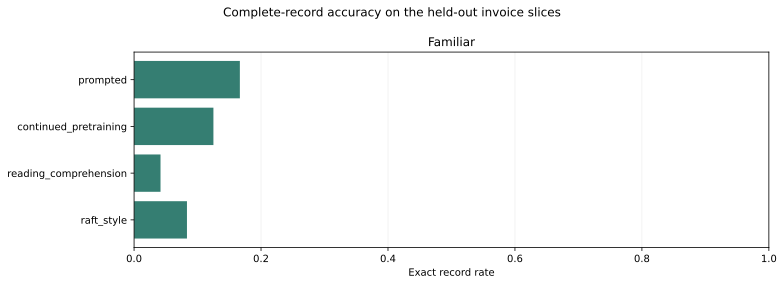

76089

In [13]:
summary={}
for method,result in scores.items():
    items=result["evidence"]
    summary[method]={}
    for label in ("present","missing"):
        chosen=[item for item in items if item["slice"]==label]
        summary[method][label]={"n":len(chosen),**{
            metric:sum(i[metric] for i in chosen)/len(chosen)
            for metric in ("valid","answer","evidence","exact","abstained")}}
    summary[method]["evidence_text_nll"]=result["evidence_text_nll"]
print(json.dumps(summary,indent=2))
extraction={name:result["extraction"] for name,result in scores.items()}
save_results(13,extraction,runs,[("prompted",name) for name in runs],
             domain_summary=summary,
             domain_paired={
                 name: {
                     label: paired_family_interval(
                         [row for row in scores["prompted"]["evidence"] if row["slice"] == label],
                         [row for row in scores[name]["evidence"] if row["slice"] == label],
                     )
                     for label in ("present", "missing")
                 }
                 for name in runs
             },
             test_pack_sha=hashlib.sha256(json.dumps([evidence_text(c) for c in fixed]).encode()).hexdigest())
(Path("results") / "13-evidence-packs.json").write_text(json.dumps([
    {"key": c.key, "family": c.family, "slice": c.slice, "question": c.question,
     "documents": c.documents, "gold": c.target} for c in fixed
], indent=2), encoding="utf-8")
(Path("results") / "13-evidence-predictions.json").write_text(json.dumps({
    name: result["evidence"] for name, result in scores.items()
}, indent=2), encoding="utf-8")

## Run it yourself

    Fix the question IDs and change the distractor source. Compare grounded exact and abstention separately, and read examples where at least one branch changed its source ID.

    [AdaptLLM](https://arxiv.org/abs/2309.09530) · [RAFT](https://arxiv.org/abs/2403.10131)